# Comparación y evaluación de modelos para Beans

## Objetivo
Comparar las configuraciones seleccionadas de CNN propia, MobileNetV2,
EfficientNetB0 y DenseNet121 sobre las mismas imágenes de validación.

La comparación considera métricas globales, desempeño por clase,
matrices de confusión, curvas de aprendizaje y costo computacional.

Se cargan modelos guardados; no se realizan nuevos entrenamientos.
Test no interviene en esta comparación. Existe una evaluación previa
de Test registrada para MobileNetV2, que se excluye de la selección.

In [15]:
# PASO 1: Importaciones para la evaluación común.
import csv
import json
from pathlib import Path
from zipfile import ZipFile
from datetime import datetime
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("TensorFlow:", tf.__version__)
print("Evaluación de modelos guardados; no habrá entrenamiento.")

TensorFlow: 2.21.0
Evaluación de modelos guardados; no habrá entrenamiento.


In [14]:
# PASO 2: Rutas, archivos y tiempos de los cuatro finalistas.
actual = Path.cwd()
carpeta_beans = actual if actual.name.lower() == "beans" else actual / "beans"

if not (carpeta_beans / "Preparacion_Beans.ipynb").is_file():
    raise FileNotFoundError("Ejecuta desde la raíz del proyecto o desde beans.")

raiz = carpeta_beans / "resultados"
clases = ["angular_leaf_spot", "bean_rust", "healthy"]
nombres_clases = ["Mancha angular", "Roya", "Sana"]

def leer_json(ruta):
    with ruta.open(encoding="utf-8") as archivo:
        return json.load(archivo)

cnn = raiz / "cnn_propia/ensayo_01_20261121_201833_819806"
mobile = raiz / "mobilenetv2/ajuste_fino_20261121_181000_639966"
efficient = raiz / "efficientnetb0/ajuste_fino_20261116_205113"
dense = raiz / "densenet121/ensayo_03_ajuste_reducido_20261121_230401_210539"

mobile_base = raiz / "mobilenetv2/base_con_aumento_20261121_174335_517871"
efficient_base = raiz / "efficientnetb0/corrida_20261116_204929"
dense_origen = raiz / "densenet121/ensayo_02_continuacion_20261121_224702_513107"
with (raiz / "efficientnetb0" / "tiempos_entrenamiento.csv").open(
    encoding="utf-8-sig", newline=""
) as archivo:
    segundos_efficientnet = next(
        float(f["tiempo_medido_s"])
        for f in csv.DictReader(archivo)
        if f["ensayo"] == "1+2"
    )

finalistas = [
    {
        "nombre": "CNN propia", "carpeta": cnn,
        "prefijos": [],
        "segundos_train": leer_json(cnn / "resumen_entrenamiento.json")[
            "segundos_entrenamiento"
        ],
    },
    {
        "nombre": "MobileNetV2", "carpeta": mobile,
        "prefijos": [(mobile_base, None)],
        "segundos_train": sum(
            leer_json(p / "entrenamiento.json")["tiempo_entrenamiento_segundos"]
            for p in (mobile_base, mobile)
        ),
    },
    {
        "nombre": "EfficientNetB0", "carpeta": efficient,
        "prefijos": [(efficient_base, None)],
        "segundos_train": segundos_efficientnet,
    },
    {
        "nombre": "DenseNet121", "carpeta": dense,
        # El ajuste fino parte del checkpoint 9, no de la época 10.
        "prefijos": [(dense_origen, 9)],
        "segundos_train": leer_json(dense / "resumen_entrenamiento.json")[
            "segundos_entrenamiento"
        ],
    },
]

for candidato in finalistas:
    carpeta = candidato["carpeta"]
    for nombre in ("mejor_modelo.keras", "historial.csv", "metricas_validation.json"):
        if not (carpeta / nombre).is_file():
            raise FileNotFoundError(carpeta / nombre)
    print(candidato["nombre"], "→", carpeta.name)

salida = (
    raiz / "comparacion_modelos"
    / datetime.now().strftime("validation_%Y%m%d_%H%M%S_%f")
)
salida.mkdir(parents=True, exist_ok=False)

print("\nResultados nuevos en:", salida.resolve())
print(
    f"Tiempo de EfficientNetB0: "
    f"{segundos_efficientnet / 60:.2f} min (registro CSV)."
)
print("El archivo de Test de MobileNetV2 no se leerá.")

with (salida / "protocolo.json").open("w", encoding="utf-8") as archivo:
    json.dump({
        "particion_evaluada": "validation",
        "clases": clases,
        "test_previo_registrado": (mobile / "metricas_test.json").is_file(),
        "resultados_test_excluidos_de_seleccion": True,
        "modelos": {
            c["nombre"]: str(c["carpeta"].resolve()) for c in finalistas
        },
    }, archivo, ensure_ascii=False, indent=2)

CNN propia → ensayo_01_20261121_201833_819806
MobileNetV2 → ajuste_fino_20261121_181000_639966
EfficientNetB0 → ajuste_fino_20261116_205113
DenseNet121 → ensayo_03_ajuste_reducido_20261121_230401_210539

Resultados nuevos en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\beans\resultados\comparacion_modelos\validation_20261122_184949_012897
Tiempo de EfficientNetB0: 3.26 min (registro CSV).
El archivo de Test de MobileNetV2 no se leerá.


In [16]:
# PASO 3: Cargar las mismas 133 imágenes de Validation.
url_validation = (
    "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/"
    "27aa014ce09b193e1a6f58112d4a66e0eddb69c5/data/validation.zip"
)

ruta_zip = keras.utils.get_file(
    fname="validation.zip",
    origin=url_validation,
    file_hash="90b7aa1c26d91d9afff07a30bbc67a5ea34f1f1397f068d8675be09d7d0c602d",
    hash_algorithm="sha256",
    cache_subdir="datasets/beans_makerere",
)

imagenes_lista, etiquetas_lista, identificadores = [], [], []

with ZipFile(ruta_zip) as archivo:
    nombres = sorted(
        nombre for nombre in archivo.namelist()
        if nombre.endswith(".jpg")
    )
    for nombre in nombres:
        clase = nombre.split("/")[-2]
        imagen = tf.io.decode_jpeg(archivo.read(nombre), channels=3)
        imagen = tf.image.resize(imagen, (224, 224), antialias=True)
        imagen = tf.clip_by_value(imagen, 0.0, 255.0)

        imagenes_lista.append(imagen.numpy())
        etiquetas_lista.append(clases.index(clase))
        identificadores.append(nombre)

imagenes_eval = np.stack(imagenes_lista)
reales_eval = np.asarray(etiquetas_lista, dtype=int)

if not np.array_equal(
    np.bincount(reales_eval, minlength=3), [44, 45, 44]
):
    raise ValueError("La partición no coincide con Validation de Beans.")

datos_eval = tf.data.Dataset.from_tensor_slices(
    (imagenes_eval, reales_eval)
).batch(32).prefetch(tf.data.AUTOTUNE)

with (salida / "imagenes_validation.csv").open(
    "w", encoding="utf-8-sig", newline=""
) as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(["imagen", "clase_real"])
    escritor.writerows(
        (nombre, clases[etiqueta])
        for nombre, etiqueta in zip(identificadores, reales_eval)
    )

print("Imágenes:", imagenes_eval.shape)
print("Conteos por clase:", np.bincount(reales_eval, minlength=3))
print("Píxeles float32 entre 0 y 255. Test no se cargó.")

Imágenes: (133, 224, 224, 3)
Conteos por clase: [44 45 44]
Píxeles float32 entre 0 y 255. Test no se cargó.


In [17]:
# PASO 4: Evaluar los cuatro checkpoints bajo las mismas condiciones.
resultados = []
detalles = {}

def auc_binaria(etiquetas, puntuaciones):
    positivos = puntuaciones[etiquetas]
    negativos = puntuaciones[~etiquetas]
    return float(
        (positivos[:, None] > negativos[None, :]).mean()
        + 0.5 * (positivos[:, None] == negativos[None, :]).mean()
    )

for candidato in finalistas:
    nombre = candidato["nombre"]
    print(f"\nEvaluando {nombre}...")

    keras.backend.clear_session()
    modelo = keras.models.load_model(
        candidato["carpeta"] / "mejor_modelo.keras", compile=False
    )

    # Preparar la primera llamada antes de medir la evaluación.
    modelo(imagenes_eval[:1], training=False)

    inicio = perf_counter()
    probabilidades = np.concatenate([
        modelo(imagenes, training=False).numpy()
        for imagenes, _ in datos_eval
    ])
    segundos_eval = perf_counter() - inicio

    if (
        probabilidades.shape != (133, 3)
        or not np.isfinite(probabilidades).all()
        or not np.allclose(probabilidades.sum(axis=1), 1, atol=1e-4)
    ):
        raise ValueError(f"Predicciones inválidas en {nombre}.")

    predichas = probabilidades.argmax(axis=1)
    matriz = np.zeros((3, 3), dtype=int)
    np.add.at(matriz, (reales_eval, predichas), 1)

    anterior = leer_json(
        candidato["carpeta"] / "metricas_validation.json"
    )
    if not np.array_equal(matriz, anterior["matriz_confusion"]):
        raise ValueError(
            f"{nombre}: la matriz no coincide con su evaluación anterior. "
            "Revisar antes de continuar."
        )

    aciertos = matriz.diagonal()
    reales = matriz.sum(axis=1)
    predicciones = matriz.sum(axis=0)
    precision = aciertos / np.maximum(predicciones, 1)
    recall = aciertos / reales
    f1 = 2 * aciertos / np.maximum(reales + predicciones, 1)

    perdida = float(-np.log(np.clip(
        probabilidades[np.arange(133), reales_eval], 1e-7, 1
    )).mean())

    auc = float(np.mean([
        auc_binaria(reales_eval == i, probabilidades[:, i])
        for i in range(3)
    ]))

    resultado = {
        "modelo": nombre,
        "exactitud": float(aciertos.sum() / 133),
        "precision_macro": float(precision.mean()),
        "recall_macro": float(recall.mean()),
        "f1_macro": float(f1.mean()),
        "roc_auc_macro_ovr": auc,
        "perdida": perdida,
        "enfermas_como_sanas": int(matriz[:2, 2].sum()),
        "parametros": int(modelo.count_params()),
        "minutos_train_acumulados": (
            candidato["segundos_train"] / 60
            if candidato["segundos_train"] is not None else None
        ),
        "segundos_evaluacion": segundos_eval,
    }
    resultados.append(resultado)
    detalles[nombre] = {
        "matriz": matriz.tolist(),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
    }

    with (salida / f"predicciones_{nombre.replace(' ', '_')}.csv").open(
        "w", encoding="utf-8-sig", newline=""
    ) as archivo:
        escritor = csv.writer(archivo)
        escritor.writerow(
            ["imagen", "real", "predicha"] + [f"prob_{c}" for c in clases]
        )
        escritor.writerows(
            [identificadores[i], clases[reales_eval[i]], clases[predichas[i]]]
            + probabilidades[i].tolist()
            for i in range(133)
        )

    print(
        f"{nombre}: {resultado['exactitud']:.2%} · "
        f"F1 macro {resultado['f1_macro']:.4f}"
    )
    del modelo

with (salida / "comparacion_validation.csv").open(
    "w", encoding="utf-8-sig", newline=""
) as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(resultados[0]))
    escritor.writeheader()
    escritor.writerows(resultados)

with (salida / "detalle_por_clase.json").open(
    "w", encoding="utf-8"
) as archivo:
    json.dump(detalles, archivo, ensure_ascii=False, indent=2)

print("\nMODELO              ACC   P MACRO   R MACRO  F1 MACRO  ROC-AUC  PÉRDIDA")
for r in resultados:
    print(
        f"{r['modelo']:<17}{r['exactitud']:>8.2%}"
        f"{r['precision_macro']:>10.4f}{r['recall_macro']:>10.4f}"
        f"{r['f1_macro']:>10.4f}{r['roc_auc_macro_ovr']:>9.4f}"
        f"{r['perdida']:>9.4f}"
    )

print("\nMODELO             PARÁMETROS  MIN TRAIN ACUM.  ENFERMAS→SANAS")
for r in resultados:
    tiempo = (
        f"{r['minutos_train_acumulados']:.2f}"
        if r["minutos_train_acumulados"] is not None else "N/D"
    )
    print(
        f"{r['modelo']:<17}{r['parametros']:>11}"
        f"{tiempo:>17}{r['enfermas_como_sanas']:>16}"
    )

print("\nMODELO             CLASE                 PRECISIÓN   RECALL       F1")
for nombre, detalle in detalles.items():
    for i, clase in enumerate(clases):
        print(
            f"{nombre:<19}{clase:<21}"
            f"{detalle['precision'][i]:>9.2%}"
            f"{detalle['recall'][i]:>9.2%}"
            f"{detalle['f1'][i]:>9.4f}"
        )

print("\nLos tiempos proceden de las ejecuciones originales.")
print("No representan una comparación controlada de velocidad entre equipos.")


Evaluando CNN propia...
CNN propia: 87.97% · F1 macro 0.8802

Evaluando MobileNetV2...
MobileNetV2: 94.74% · F1 macro 0.9474

Evaluando EfficientNetB0...
EfficientNetB0: 91.73% · F1 macro 0.9176

Evaluando DenseNet121...
DenseNet121: 94.74% · F1 macro 0.9462

MODELO              ACC   P MACRO   R MACRO  F1 MACRO  ROC-AUC  PÉRDIDA
CNN propia         87.97%    0.8812    0.8798    0.8802   0.9739   0.3356
MobileNetV2        94.74%    0.9495    0.9473    0.9474   0.9943   0.1576
EfficientNetB0     91.73%    0.9229    0.9170    0.9176   0.9915   0.1720
DenseNet121        94.74%    0.9522    0.9470    0.9462   0.9825   0.2735

MODELO             PARÁMETROS  MIN TRAIN ACUM.  ENFERMAS→SANAS
CNN propia            328419            11.34               4
MobileNetV2          2261827             4.95               1
EfficientNetB0       4053414             3.26               1
DenseNet121          7040579             8.86               2

MODELO             CLASE                 PRECISIÓN   RECAL

CNN propia · inicio de etapa final: 1 · checkpoint en la trayectoria: 21
MobileNetV2 · inicio de etapa final: 6 · checkpoint en la trayectoria: 11
EfficientNetB0 · inicio de etapa final: 6 · checkpoint en la trayectoria: 7
DenseNet121 · inicio de etapa final: 10 · checkpoint en la trayectoria: 15


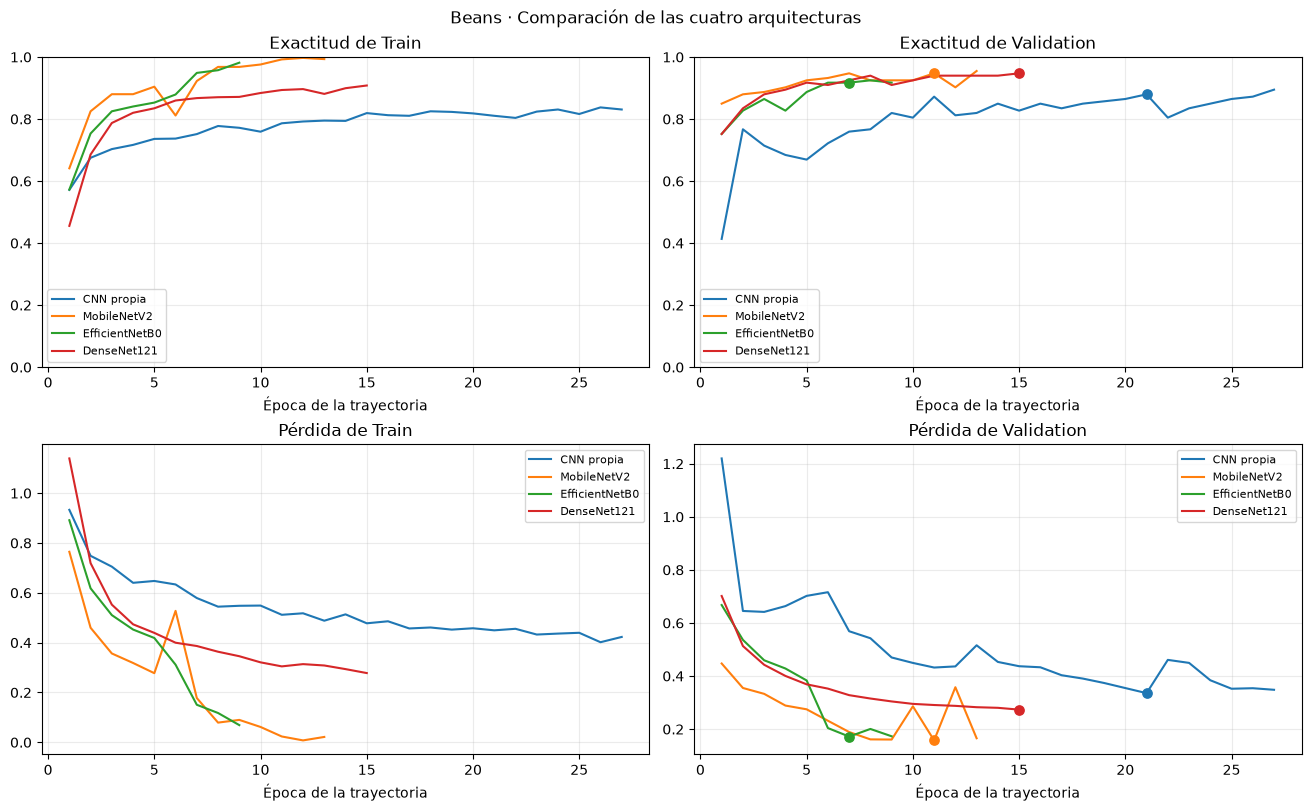

Los puntos de Validation identifican los checkpoints evaluados.
Las trayectorias incluyen continuaciones y ajustes finos.
Las épocas no representan el mismo tiempo ni capacidad entrenable.
Las curvas de Train y Validation utilizan distintas condiciones.


In [18]:
# PASO 5: Curvas comparativas con las trayectorias de los finalistas.
def leer_historial(carpeta):
    with (carpeta / "historial.csv").open(
        encoding="utf-8-sig", newline=""
    ) as archivo:
        return list(csv.DictReader(archivo))

fig, ejes = plt.subplots(
    2, 2, figsize=(13, 8), layout="constrained"
)
fig.suptitle("Beans · Comparación de las cuatro arquitecturas")

for candidato in finalistas:
    registros = []
    for carpeta, limite in candidato["prefijos"]:
        anteriores = leer_historial(carpeta)
        registros.extend(
            anteriores if limite is None else anteriores[:limite]
        )

    inicio_etapa_final = len(registros)
    ultima_etapa = leer_historial(candidato["carpeta"])
    registros.extend(ultima_etapa)

    checkpoint = inicio_etapa_final + min(
        range(len(ultima_etapa)),
        key=lambda i: float(ultima_etapa[i]["val_loss"]),
    ) + 1

    epocas = np.arange(1, len(registros) + 1)
    for eje, metrica, titulo in zip(
        ejes.flat,
        ("accuracy", "val_accuracy", "loss", "val_loss"),
        ("Exactitud de Train", "Exactitud de Validation",
         "Pérdida de Train", "Pérdida de Validation"),
    ):
        valores = [float(f[metrica]) for f in registros]
        linea, = eje.plot(epocas, valores, label=candidato["nombre"])
        if metrica.startswith("val_"):
            eje.scatter(
                checkpoint, valores[checkpoint - 1],
                color=linea.get_color(), s=45, zorder=3,
            )
        eje.set(title=titulo, xlabel="Época de la trayectoria")
        eje.grid(alpha=0.25)
        eje.legend(fontsize=8)

    print(
        candidato["nombre"],
        "· inicio de etapa final:", inicio_etapa_final + 1,
        "· checkpoint en la trayectoria:", checkpoint,
    )

for eje in ejes[0]:
    eje.set_ylim(0, 1)

fig.savefig(salida / "curvas_comparativas.png", dpi=200)
plt.show()
plt.close(fig)

print("Los puntos de Validation identifican los checkpoints evaluados.")
print("Las trayectorias incluyen continuaciones y ajustes finos.")
print("Las épocas no representan el mismo tiempo ni capacidad entrenable.")
print("Las curvas de Train y Validation utilizan distintas condiciones.")

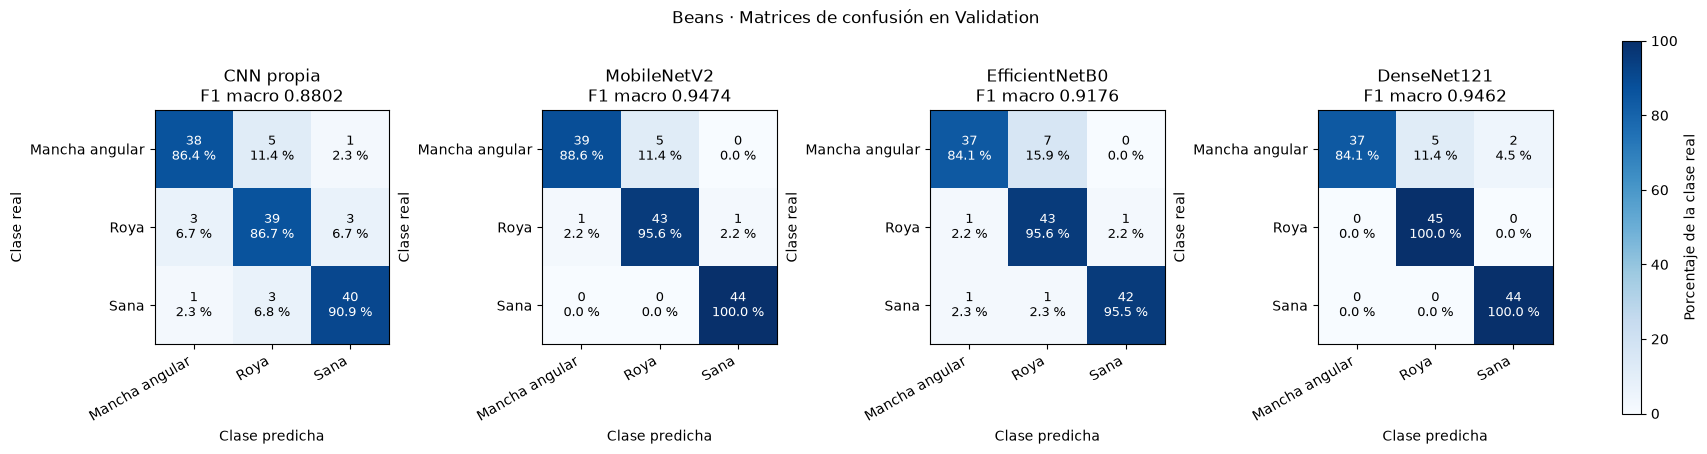

Comparación terminada. Todavía no se registró un ganador.
Evidencia guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\beans\resultados\comparacion_modelos\validation_20261122_184949_012897


In [19]:
# PASO 6: Matrices de los cuatro modelos en Validation.
fig, ejes = plt.subplots(
    1, 4, figsize=(17, 4.5), layout="constrained"
)
fig.suptitle("Beans · Matrices de confusión en Validation")
etiquetas_cortas = ["Mancha angular", "Roya", "Sana"]

for eje, resultado in zip(ejes, resultados):
    nombre = resultado["modelo"]
    matriz = np.asarray(detalles[nombre]["matriz"])
    porcentajes = 100 * matriz / matriz.sum(axis=1, keepdims=True)

    imagen = eje.imshow(porcentajes, cmap="Blues", vmin=0, vmax=100)
    eje.set_xticks(range(3), etiquetas_cortas, rotation=30, ha="right")
    eje.set_yticks(range(3), etiquetas_cortas)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
    eje.set_title(f"{nombre}\nF1 macro {resultado['f1_macro']:.4f}")

    for i, j in np.ndindex(matriz.shape):
        eje.text(
            j, i, f"{matriz[i, j]}\n{porcentajes[i, j]:.1f} %",
            ha="center", va="center",
            color="white" if porcentajes[i, j] > 50 else "black",
            fontsize=9,
        )

fig.colorbar(imagen, ax=list(ejes), label="Porcentaje de la clase real")
fig.savefig(salida / "matrices_comparativas.png", dpi=200)
plt.show()
plt.close(fig)

print("Comparación terminada. Todavía no se registró un ganador.")
print("Evidencia guardada en:", salida.resolve())

In [20]:
# PASO 7: Registrar la selección final para Beans.
nombre_seleccionado = "MobileNetV2"

candidato_seleccionado = next(
    c for c in finalistas if c["nombre"] == nombre_seleccionado
)
metricas_seleccionadas = next(
    r for r in resultados if r["modelo"] == nombre_seleccionado
)
ruta_modelo_seleccionado = (
    candidato_seleccionado["carpeta"] / "mejor_modelo.keras"
)

justificacion = """
Se selecciona MobileNetV2 por su equilibrio entre clasificación y costo:
iguala los 126 aciertos de DenseNet121, utiliza menos parámetros,
presenta menor pérdida y clasifica una enferma menos como sana.

La diferencia de F1 macro es pequeña y no constituye el único criterio.
DenseNet121 presenta curvas más estables y mayor recall de roya.
MobileNetV2 muestra oscilaciones y señales de sobreajuste al final;
se conserva su checkpoint de la época 6 del ajuste fino, no la última.

La selección utiliza Validation. No se consultaron las métricas de Test
durante esta comparación. Existe una evaluación previa de Test registrada
para MobileNetV2, que debe declararse como limitación del protocolo.
"""

seleccion_beans = {
    "modelo": nombre_seleccionado,
    "carpeta_modelo_relativa_a_beans": str(
        candidato_seleccionado["carpeta"].relative_to(carpeta_beans)
    ),
    "archivo_modelo": "mejor_modelo.keras",
    "epoca_ajuste_fino": 6,
    "metricas_validation": metricas_seleccionadas,
    "justificacion": justificacion.strip(),
}

with (salida / "seleccion_final_beans.json").open(
    "w", encoding="utf-8"
) as archivo:
    json.dump(seleccion_beans, archivo, ensure_ascii=False, indent=2)

print("Seleccionado:", nombre_seleccionado)
print(justificacion)
print("Modelo:", ruta_modelo_seleccionado.resolve())

Seleccionado: MobileNetV2

Se selecciona MobileNetV2 por su equilibrio entre clasificación y costo:
iguala los 126 aciertos de DenseNet121, utiliza menos parámetros,
presenta menor pérdida y clasifica una enferma menos como sana.

La diferencia de F1 macro es pequeña y no constituye el único criterio.
DenseNet121 presenta curvas más estables y mayor recall de roya.
MobileNetV2 muestra oscilaciones y señales de sobreajuste al final;
se conserva su checkpoint de la época 6 del ajuste fino, no la última.

La selección utiliza Validation. No se consultaron las métricas de Test
durante esta comparación. Existe una evaluación previa de Test registrada
para MobileNetV2, que debe declararse como limitación del protocolo.

Modelo: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\beans\resultados\mobilenetv2\ajuste_fino_20261121_181000_639966\mejor_modelo.keras


In [8]:
# PASO 8: Evaluación final de MobileNetV2 con Test.
url_test = (
    "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/"
    "27aa014ce09b193e1a6f58112d4a66e0eddb69c5/data/test.zip"
)

ruta_zip_test = keras.utils.get_file(
    fname="test.zip",
    origin=url_test,
    file_hash="ca67b15d960d1e2fd9d23fd8498ce86818ead90755c630a43baf19ec4af09312",
    hash_algorithm="sha256",
    cache_subdir="datasets/beans_makerere",
)

lista_imagenes_test, lista_reales_test, nombres_test = [], [], []

with ZipFile(ruta_zip_test) as archivo:
    for nombre in sorted(archivo.namelist()):
        if not nombre.lower().endswith(".jpg"):
            continue

        clase = nombre.split("/")[-2]
        imagen = tf.io.decode_jpeg(archivo.read(nombre), channels=3)
        imagen = tf.image.resize(imagen, (224, 224), antialias=True)
        imagen = tf.clip_by_value(imagen, 0.0, 255.0)

        lista_imagenes_test.append(imagen.numpy())
        lista_reales_test.append(clases.index(clase))
        nombres_test.append(nombre)

imagenes_test = np.stack(lista_imagenes_test)
reales_test = np.asarray(lista_reales_test, dtype=int)

if not np.array_equal(
    np.bincount(reales_test, minlength=3), [43, 43, 42]
):
    raise ValueError("La partición no coincide con Test de Beans.")

modelo_test = keras.models.load_model(
    ruta_modelo_seleccionado, compile=False
)

# El modelo guardado incluye su normalización.
probabilidades_test = np.concatenate([
    modelo_test(imagenes_test[i:i + 32], training=False).numpy()
    for i in range(0, len(imagenes_test), 32)
])

if (
    probabilidades_test.shape != (128, 3)
    or not np.isfinite(probabilidades_test).all()
    or not np.allclose(probabilidades_test.sum(axis=1), 1, atol=1e-4)
):
    raise ValueError("Las probabilidades de Test no son válidas.")

predichas_test = probabilidades_test.argmax(axis=1)
matriz_test = np.zeros((3, 3), dtype=int)
np.add.at(matriz_test, (reales_test, predichas_test), 1)

aciertos_test = matriz_test.diagonal()
conteos_test = matriz_test.sum(axis=1)
predicciones_test = matriz_test.sum(axis=0)

precision_test = aciertos_test / np.maximum(predicciones_test, 1)
recall_test = aciertos_test / conteos_test
f1_test = (
    2 * aciertos_test
    / np.maximum(conteos_test + predicciones_test, 1)
)

metricas_test = {
    "modelo": nombre_seleccionado,
    "particion": "test",
    "imagenes": len(reales_test),
    "exactitud": float(aciertos_test.sum() / len(reales_test)),
    "precision_macro": float(precision_test.mean()),
    "recall_macro": float(recall_test.mean()),
    "f1_macro": float(f1_test.mean()),
    "roc_auc_macro_ovr": float(np.mean([
        auc_binaria(reales_test == i, probabilidades_test[:, i])
        for i in range(3)
    ])),
    "perdida": float(-np.log(np.clip(
        probabilidades_test[np.arange(len(reales_test)), reales_test],
        1e-7, 1,
    )).mean()),
    "enfermas_como_sanas": int(matriz_test[:2, 2].sum()),
    "matriz_confusion": matriz_test.tolist(),
    "por_clase": {
        clase: {
            "aciertos": int(aciertos_test[i]),
            "total": int(conteos_test[i]),
            "precision": float(precision_test[i]),
            "recall": float(recall_test[i]),
            "f1": float(f1_test[i]),
        }
        for i, clase in enumerate(clases)
    },
    "evaluacion_previa_test_registrada": (
        candidato_seleccionado["carpeta"] / "metricas_test.json"
    ).is_file(),
    "seleccion_realizada_con": "validation",
}

salida_test = salida / "test_modelo_seleccionado"
salida_test.mkdir(exist_ok=True)

with (salida_test / "metricas_test.json").open(
    "w", encoding="utf-8"
) as archivo:
    json.dump(metricas_test, archivo, ensure_ascii=False, indent=2)

with (salida_test / "predicciones_test.csv").open(
    "w", encoding="utf-8-sig", newline=""
) as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(
        ["imagen", "real", "predicha"] + [f"prob_{c}" for c in clases]
    )
    escritor.writerows(
        [nombres_test[i], clases[reales_test[i]], clases[predichas_test[i]]]
        + probabilidades_test[i].tolist()
        for i in range(len(reales_test))
    )

print(f"{nombre_seleccionado} · EVALUACIÓN EN TEST")
print("Imágenes:", len(reales_test))
print(f"Aciertos: {aciertos_test.sum()}/{len(reales_test)}")
print(f"Exactitud: {metricas_test['exactitud']:.2%}")

for clave, etiqueta in (
    ("precision_macro", "Precisión macro"),
    ("recall_macro", "Recall macro"),
    ("f1_macro", "F1 macro"),
    ("roc_auc_macro_ovr", "ROC-AUC macro OvR"),
    ("perdida", "Pérdida"),
):
    print(f"{etiqueta}: {metricas_test[clave]:.4f}")

print("\nClase                 Aciertos  Precisión    Recall        F1")
for i, clase in enumerate(clases):
    aciertos = f"{aciertos_test[i]}/{conteos_test[i]}"
    print(
        f"{clase:<22}{aciertos:>8}"
        f"{precision_test[i]:>11.2%}{recall_test[i]:>10.2%}"
        f"{f1_test[i]:>10.4f}"
    )

print("\nEnfermas predichas como sanas:",
      metricas_test["enfermas_como_sanas"])
print("Resultados guardados en:", salida_test.resolve())
print("Existe una evaluación previa de Test; se declara ese antecedente.")
print("No se entrenó ni se cambió el modelo seleccionado.")

MobileNetV2 · EVALUACIÓN EN TEST
Imágenes: 128
Aciertos: 124/128
Exactitud: 96.88%
Precisión macro: 0.9696
Recall macro: 0.9690
F1 macro: 0.9690
ROC-AUC macro OvR: 0.9964
Pérdida: 0.0988

Clase                 Aciertos  Precisión    Recall        F1
angular_leaf_spot        42/43     93.33%    97.67%    0.9545
bean_rust                40/43     97.56%    93.02%    0.9524
healthy                  42/42    100.00%   100.00%    1.0000

Enfermas predichas como sanas: 0
Resultados guardados en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\beans\resultados\comparacion_modelos\validation_20261122_083005_031981\test_modelo_seleccionado
Existe una evaluación previa de Test; se declara ese antecedente.
No se entrenó ni se cambió el modelo seleccionado.


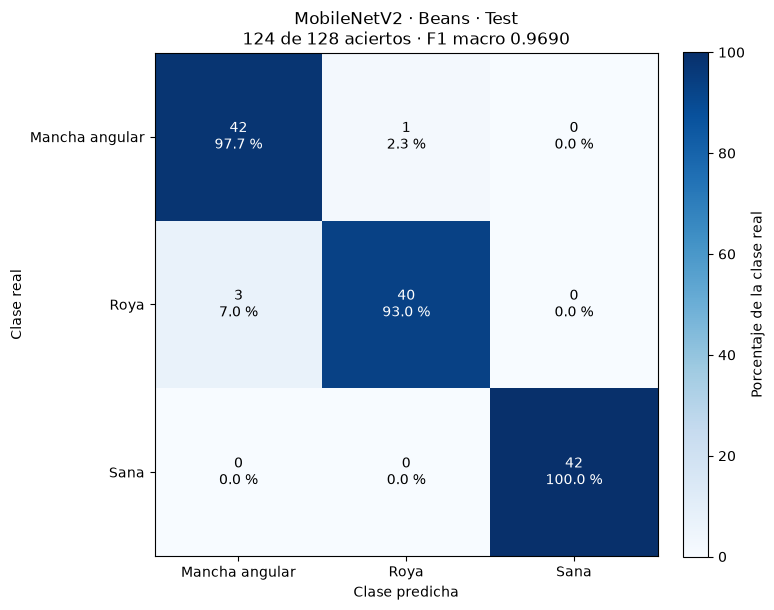

Filas: clase real. Columnas: clase predicha.
Se muestran cantidades y porcentajes dentro de cada clase real.


In [9]:
# PASO 9: Matriz de confusión de MobileNetV2 en Test.
porcentajes_test = 100 * matriz_test / conteos_test[:, None]

fig, ax = plt.subplots(
    figsize=(7.5, 6), layout="constrained"
)

imagen_matriz_test = ax.imshow(
    porcentajes_test, cmap="Blues", vmin=0, vmax=100
)
fig.colorbar(
    imagen_matriz_test, ax=ax,
    label="Porcentaje de la clase real",
)

ax.set_xticks(range(3), labels=nombres_clases)
ax.set_yticks(range(3), labels=nombres_clases)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title(
    "MobileNetV2 · Beans · Test\n"
    f"124 de 128 aciertos · F1 macro {metricas_test['f1_macro']:.4f}"
)

for real, predicha in np.ndindex(matriz_test.shape):
    porcentaje = porcentajes_test[real, predicha]
    ax.text(
        predicha, real,
        f"{matriz_test[real, predicha]}\n{porcentaje:.1f} %",
        ha="center", va="center",
        color="white" if porcentaje > 50 else "black",
    )

fig.savefig(
    salida_test / "matriz_confusion_test.png", dpi=200
)
plt.show()
plt.close(fig)

print("Filas: clase real. Columnas: clase predicha.")
print("Se muestran cantidades y porcentajes dentro de cada clase real.")

test/angular_leaf_spot/angular_leaf_spot_test.0.jpg
  Real: angular_leaf_spot | Predicha: angular_leaf_spot | Probabilidad: 99.99%

test/bean_rust/bean_rust_test.0.jpg
  Real: bean_rust | Predicha: bean_rust | Probabilidad: 100.00%

test/healthy/healthy_test.0.jpg
  Real: healthy | Predicha: healthy | Probabilidad: 99.35%

test/angular_leaf_spot/angular_leaf_spot_test.42.jpg
  Real: angular_leaf_spot | Predicha: bean_rust | Probabilidad: 99.70%



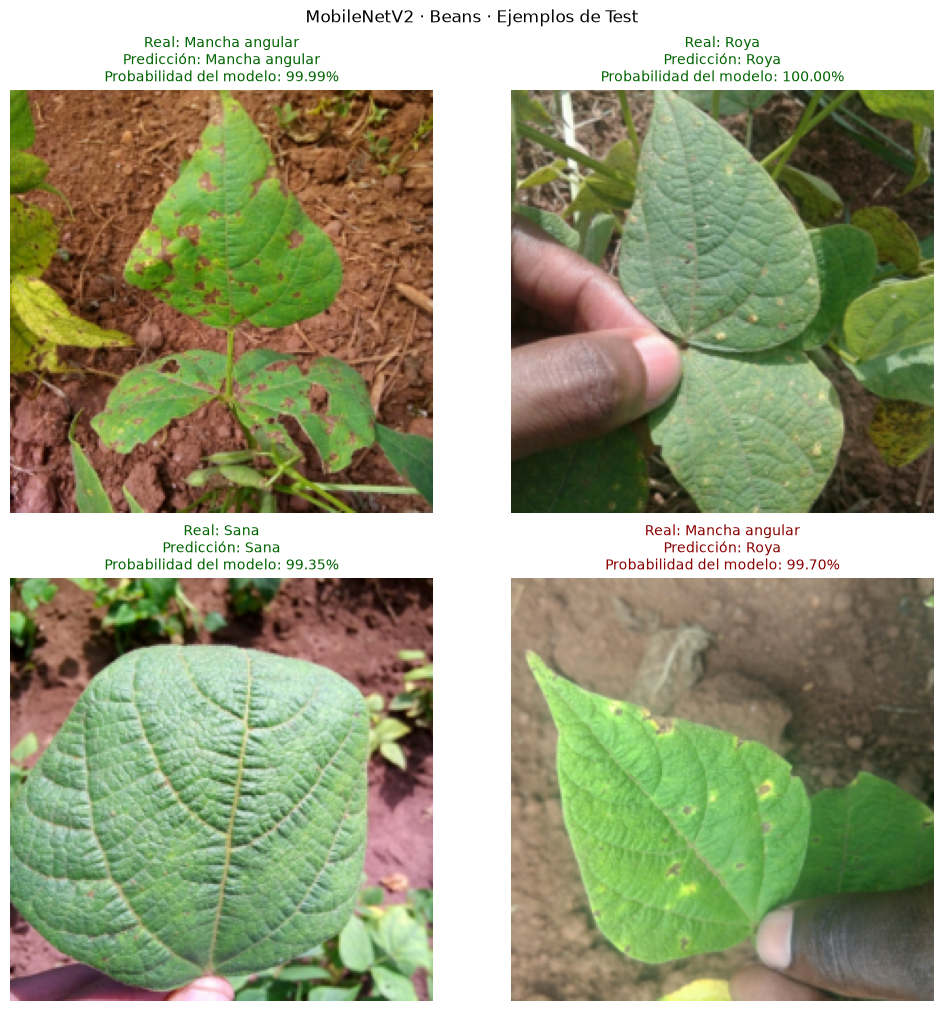

Los ejemplos son ilustrativos; las métricas usan las 128 imágenes.
La probabilidad mostrada no garantiza que la predicción sea correcta.
Figuras guardadas en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\beans\resultados\comparacion_modelos\validation_20261122_083005_031981\test_modelo_seleccionado


In [10]:
# PASO 10: Tres ejemplos, uno por clase, y un error adicional.
indices_demo_test = [
    int(np.flatnonzero(reales_test == i)[0])
    for i in range(3)
]

errores_test = np.flatnonzero(reales_test != predichas_test)

if errores_test.size:
    primer_error_test = int(errores_test[0])
    if primer_error_test not in indices_demo_test:
        indices_demo_test.append(primer_error_test)

fig, ejes = plt.subplots(
    2, 2, figsize=(10, 10), layout="constrained"
)
fig.suptitle("MobileNetV2 · Beans · Ejemplos de Test")

for ax in ejes.flat:
    ax.axis("off")

for ax, indice in zip(ejes.flat, indices_demo_test):
    real = int(reales_test[indice])
    predicha = int(predichas_test[indice])
    puntuacion = float(probabilidades_test[indice, predicha])
    acierto = real == predicha

    ax.imshow(np.clip(imagenes_test[indice] / 255.0, 0, 1))
    ax.set_title(
        f"Real: {nombres_clases[real]}\n"
        f"Predicción: {nombres_clases[predicha]}\n"
        f"Probabilidad del modelo: {puntuacion:.2%}",
        color="darkgreen" if acierto else "darkred",
        fontsize=10,
    )

    print(
        f"{nombres_test[indice]}\n"
        f"  Real: {clases[real]} | Predicha: {clases[predicha]}"
        f" | Probabilidad: {puntuacion:.2%}\n"
    )

fig.savefig(
    salida_test / "ejemplos_predicciones_test.png", dpi=200
)
plt.show()
plt.close(fig)

print("Los ejemplos son ilustrativos; las métricas usan las 128 imágenes.")
print("La probabilidad mostrada no garantiza que la predicción sea correcta.")
print("Figuras guardadas en:", salida_test.resolve())